In [12]:
import pandas as pd 
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr, chi2_contingency

# Import - traitement des données  - Analyse des données

In [2]:
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "developement" else Path.cwd()
DATA_PATH = (RACINE / "data" / "train.csv") if (RACINE / "data" / "train.csv").exists() else (RACINE / "train.csv")
initial_train_set = pd.read_csv(DATA_PATH, sep=",")


In [3]:
train = initial_train_set.copy()

train = train.drop(columns=['id_client', 'id_vehicule', 'id_contrat', 'index', 'anciennete_info',
                            'freq_paiement', 'paiement', 'utilisation', 'code_postal',
                            'marque_vehicule', 'modele_vehicule'])

cibles = ["nombre_sinistres", "montant_sinistre", "sinistre"]
a_exclure = [c for c in cibles + ["poids_manquant"] if c in train.columns]

cols_num = [c for c in train.select_dtypes(include="number").columns if c not in a_exclure]
cols_cat = [c for c in train.columns if c not in cols_num + a_exclure]

print("Train :", train.shape)
print("Numériques :", cols_num)
print("Catégorielles :", cols_cat)

Train : (50000, 22)
Numériques : ['bonus', 'duree_contrat', 'age_conducteur1', 'age_conducteur2', 'anciennete_permis1', 'anciennete_permis2', 'anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule', 'debut_vente_vehicule', 'fin_vente_vehicule', 'vitesse_vehicule', 'prix_vehicule', 'poids_vehicule']
Catégorielles : ['type_contrat', 'conducteur2', 'sex_conducteur1', 'sex_conducteur2', 'essence_vehicule', 'type_vehicule']


# Analyse 

- Variables numériques

,count,mean,std,min,1%,50%,99%,max
bonus,50000.0,0.54,0.10,0.5,0.5,0.5,0.95,2.16
duree_contrat,50000.0,11.09,8.57,1.0,1.0,9.0,31.00,41.00
age_conducteur1,50000.0,54.65,14.87,19.0,24.0,54.0,86.00,101.00
age_conducteur2,50000.0,15.57,23.99,0.0,0.0,0.0,78.00,99.00
anciennete_permis1,50000.0,32.44,13.47,1.0,4.0,32.0,61.00,111.00
anciennete_permis2,50000.0,9.14,17.06,0.0,0.0,0.0,59.00,111.00
anciennete_vehicule,49999.0,9.53,7.01,1.0,1.0,8.0,33.00,65.00
cylindre_vehicule,50000.0,1647.80,463.65,0.0,652.0,1587.0,2993.00,6997.00
din_vehicule,50000.0,91.55,34.49,15.0,30.0,87.0,210.00,500.00
debut_vente_vehicule,50000.0,11.63,7.76,1.0,1.0,10.0,41.00,74.00


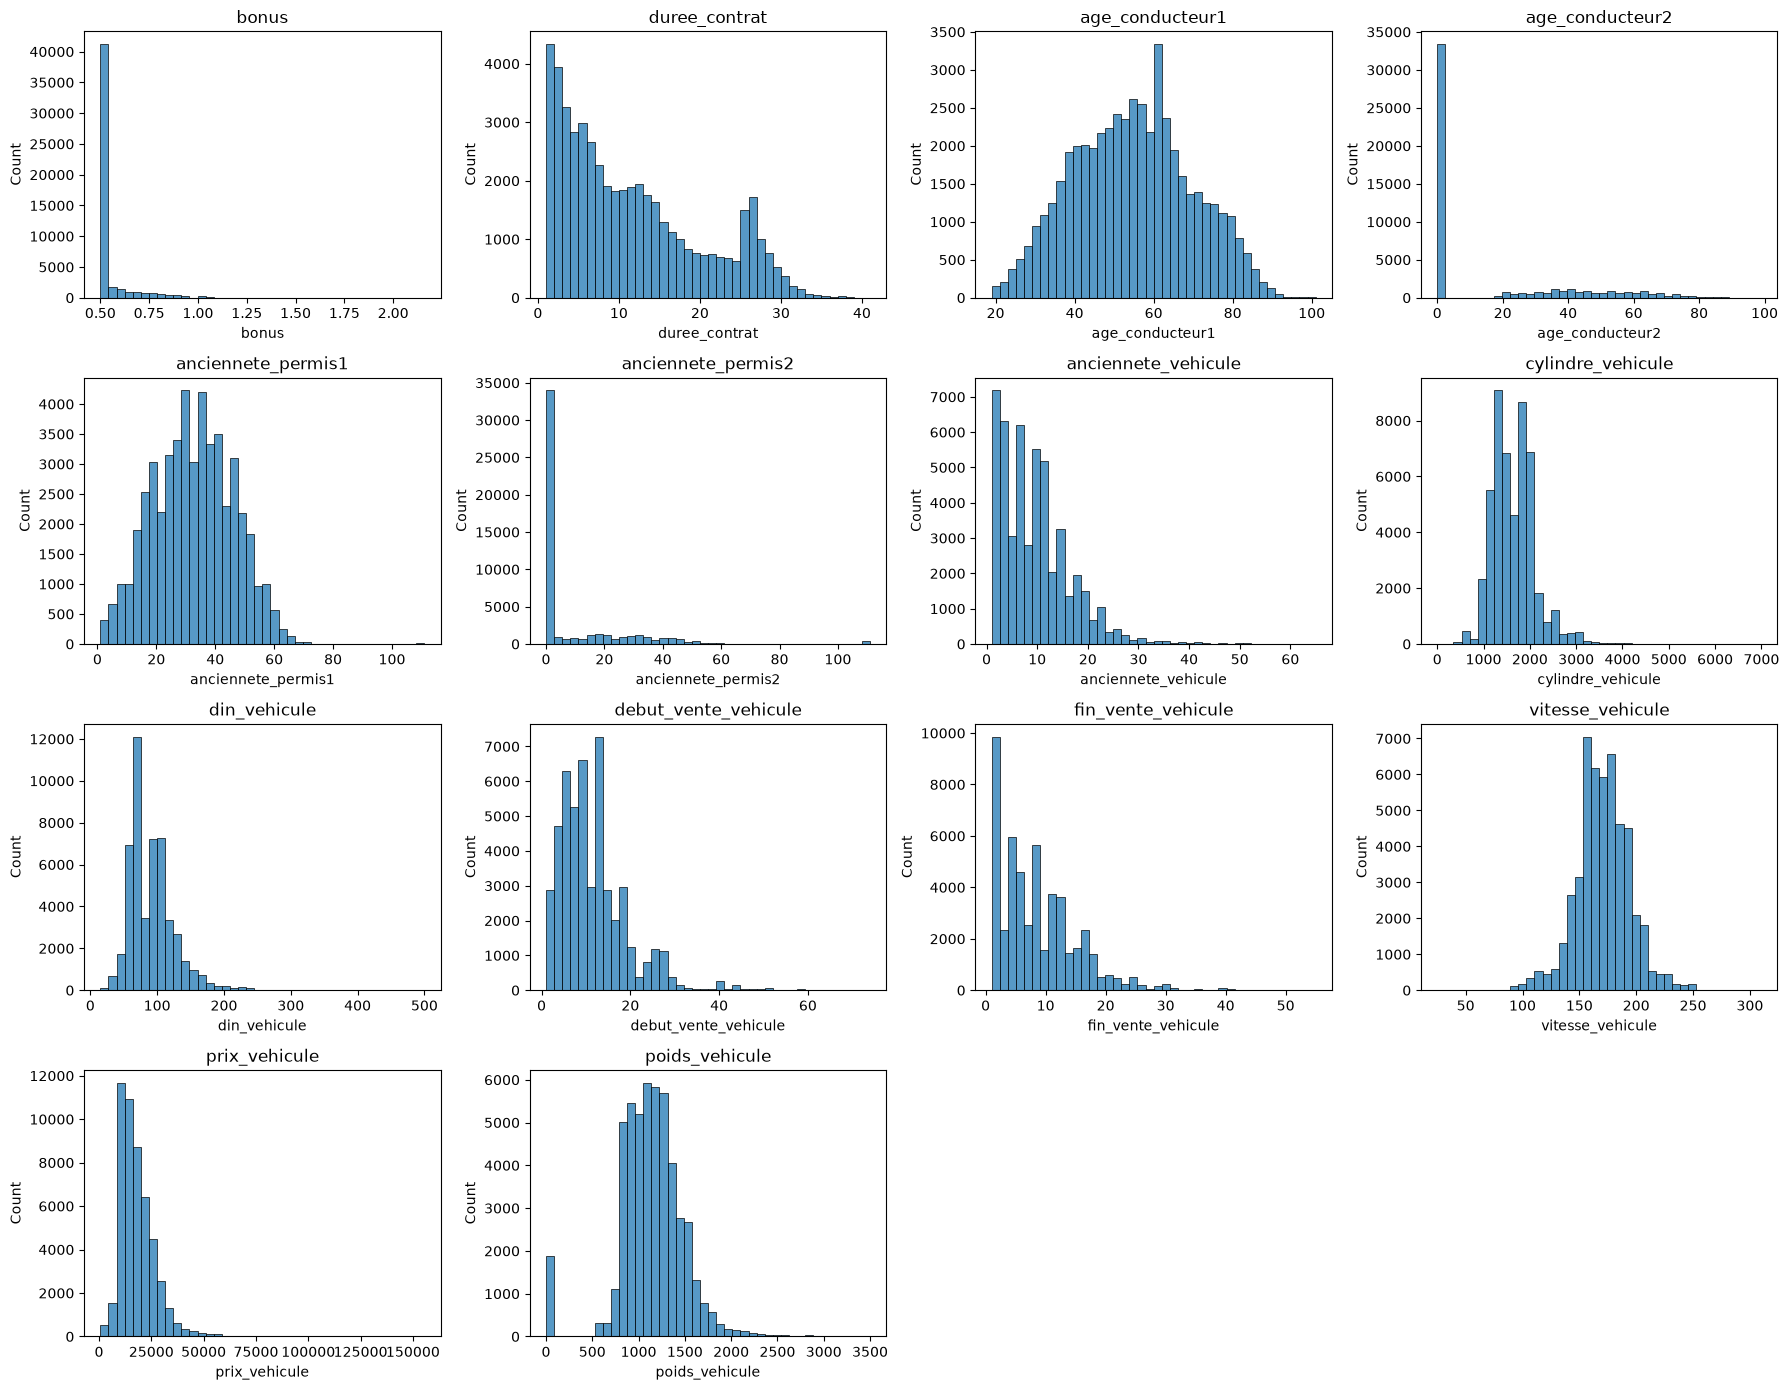

In [4]:
display(train[cols_num].describe(percentiles=[.01, .5, .99]).T.round(2))

n = len(cols_num); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 3.5 * nrow), squeeze=False)
for ax, c in zip(axes.flat, cols_num):
    sns.histplot(train[c].dropna(), bins=40, ax=ax).set_title(c)
for ax in axes.flat[n:]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

- variable catégorielle


In [5]:
for c in cols_cat:
    vc = train[c].value_counts(dropna=False)
    print(f"{c:22s} {vc.size:5d} modalités | rares (<30) : {(vc < 30).sum():4d} "
          f"| top : {vc.index[0]} ({vc.iloc[0] / len(train):.0%})")

for c in cols_cat:
    tab = pd.DataFrame({
        "effectif": train[c].value_counts(dropna=False),
        "pct": (train[c].value_counts(normalize=True, dropna=False) * 100).round(2),
    }).head(15)
    print(f"\n--- {c} ---"); display(tab)

type_contrat               4 modalités | rares (<30) :    0 | top : Maxi (65%)
conducteur2                2 modalités | rares (<30) :    0 | top : No (67%)
sex_conducteur1            2 modalités | rares (<30) :    0 | top : M (60%)
sex_conducteur2            3 modalités | rares (<30) :    0 | top : nan (67%)
essence_vehicule           3 modalités | rares (<30) :    0 | top : Diesel (55%)
type_vehicule              2 modalités | rares (<30) :    0 | top : Tourism (90%)

--- type_contrat ---


,effectif,pct
type_contrat,,
Maxi,32360,64.72
Median2,8759,17.52
Median1,4638,9.28
Mini,4243,8.49



--- conducteur2 ---


,effectif,pct
conducteur2,,
No,33406,66.81
Yes,16594,33.19



--- sex_conducteur1 ---


...

,effectif,pct
sex_conducteur2,,
NaN,33406,66.81
F,10111,20.22
M,6483,12.97



--- essence_vehicule ---


,effectif,pct
essence_vehicule,,
Diesel,27476,54.95
Gasoline,22478,44.96
Hybrid,46,0.09



--- type_vehicule ---


,effectif,pct
type_vehicule,,
Tourism,45036,90.07
Commercial,4964,9.93


- Analyse bivariée

In [6]:
train["sinistre"] = (train["nombre_sinistres"] > 0).astype(int)
print(f"Taux de sinistre global : {train['sinistre'].mean():.2%}")

Taux de sinistre global : 5.83%


- lien avec fréquence de sinistre

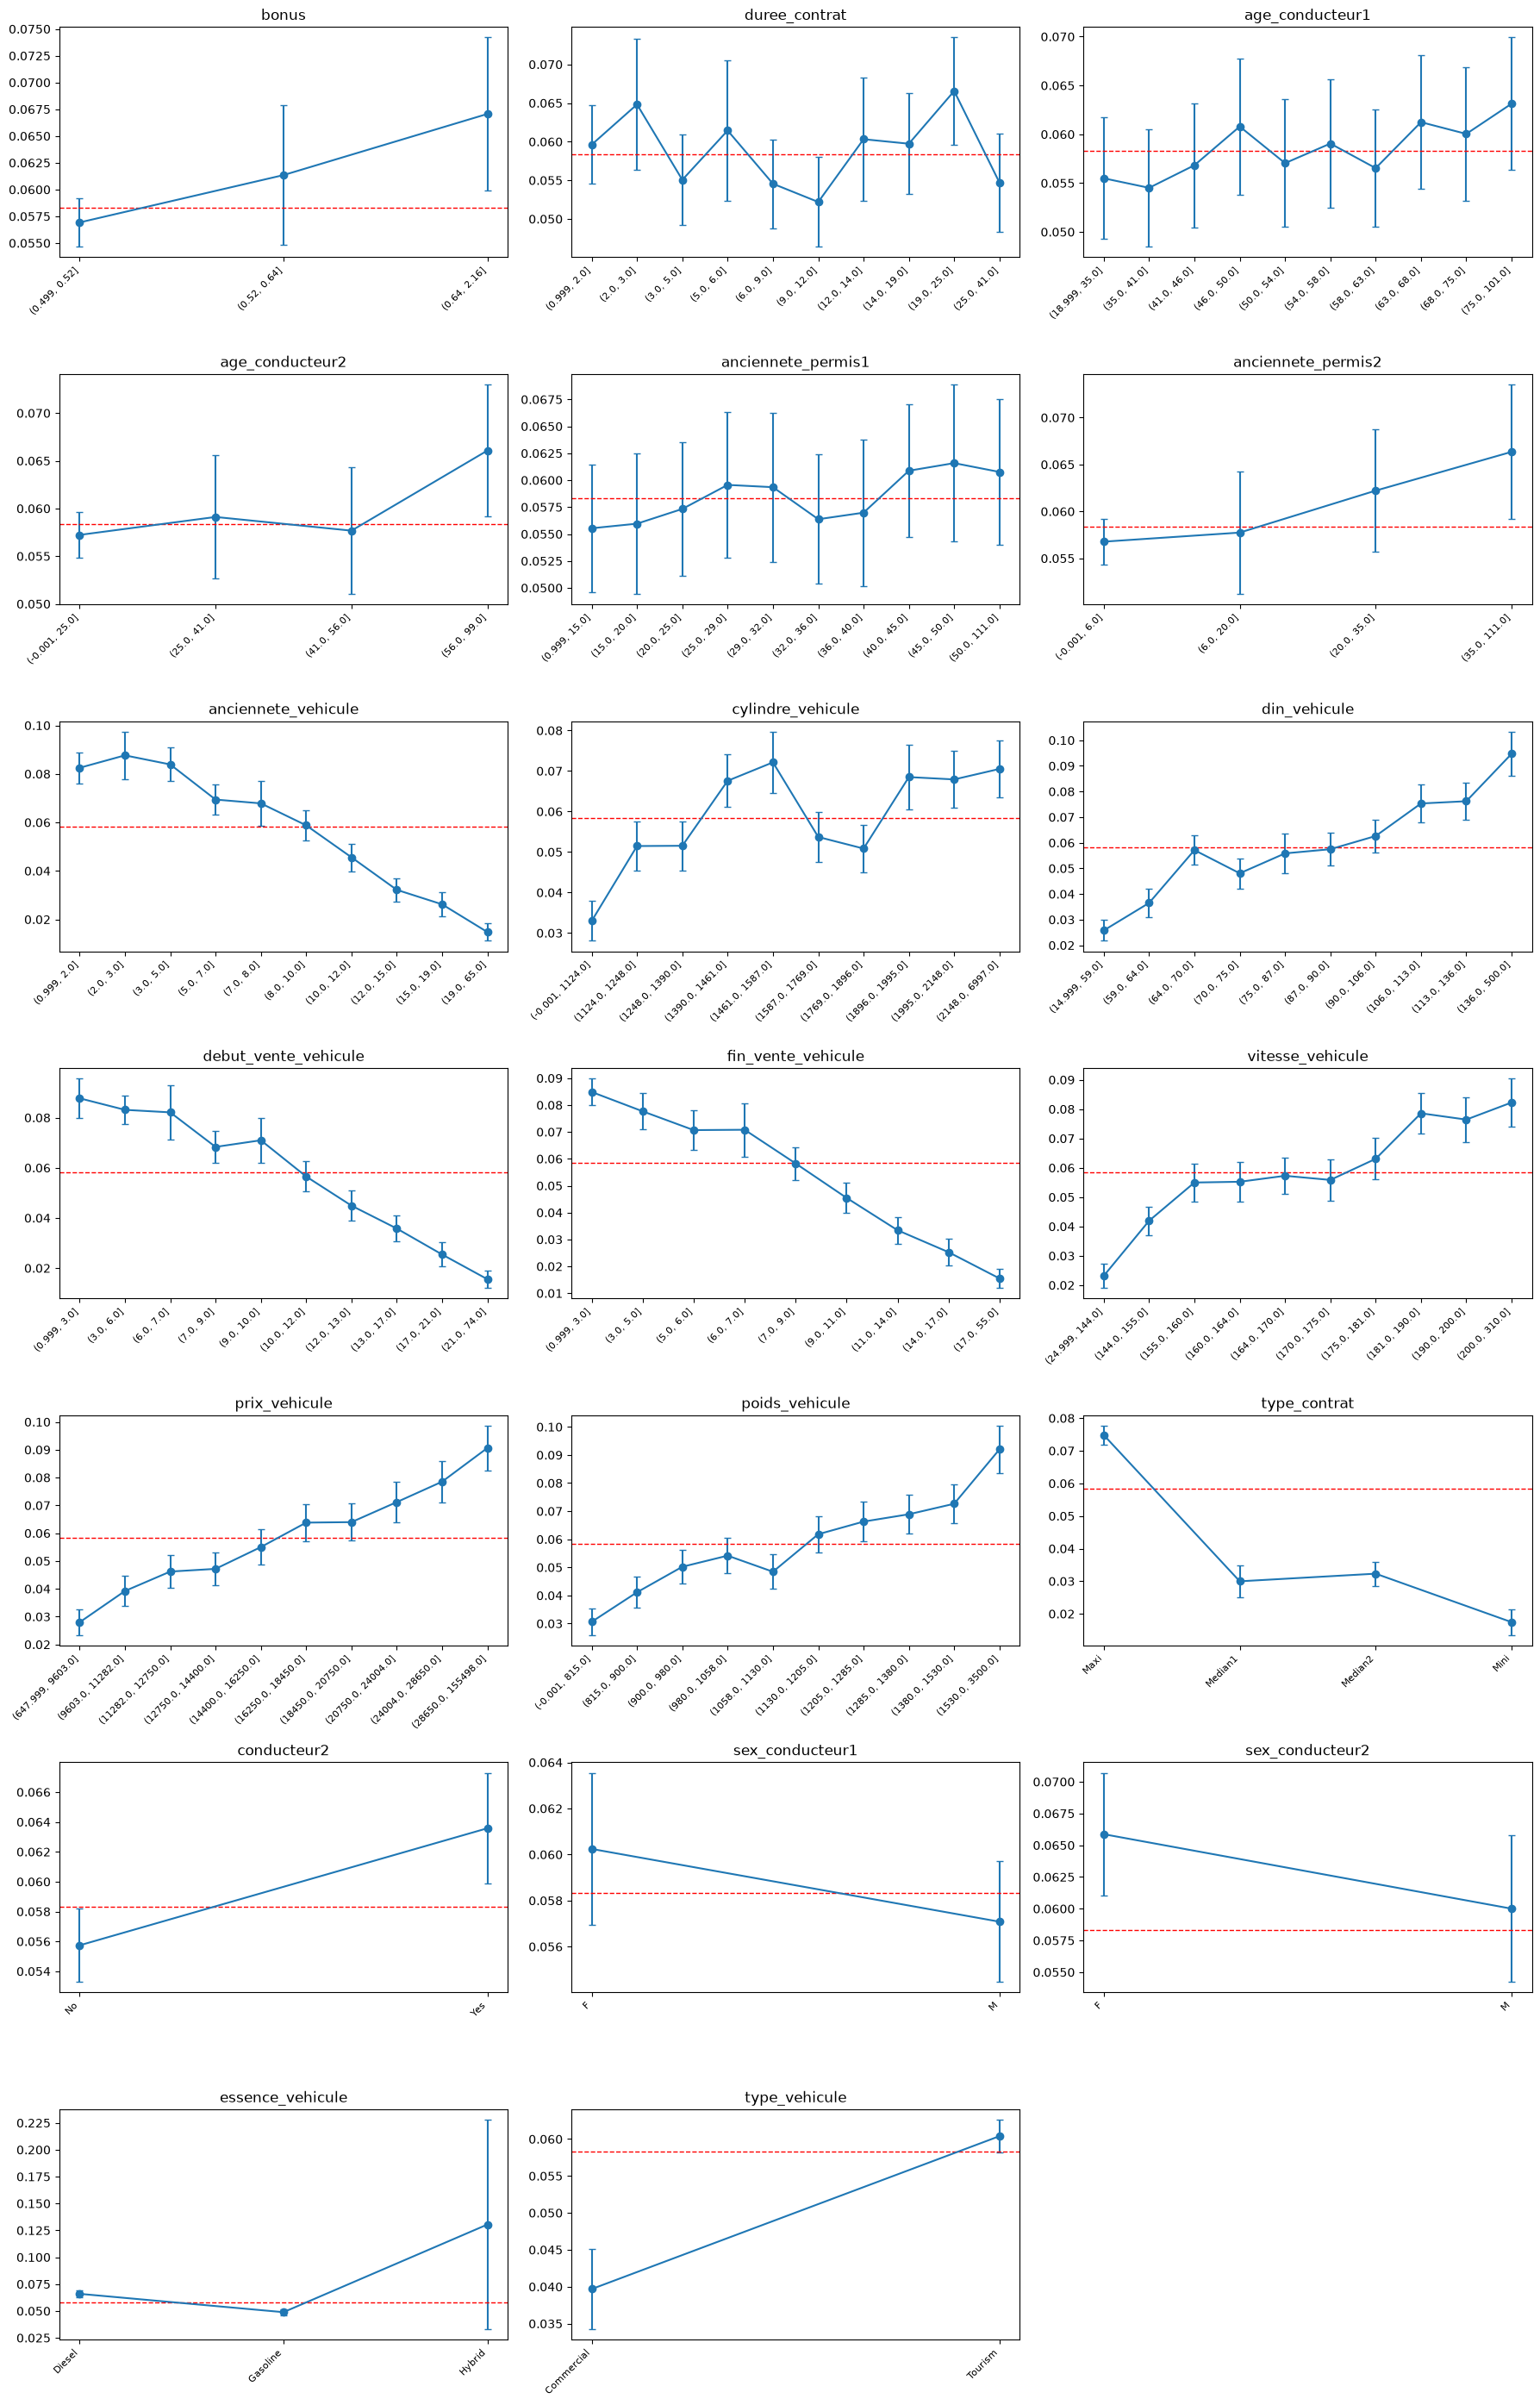

In [7]:
def taux_par_groupe(df, var, cible="sinistre", bins=None, min_eff=30):
    x = pd.qcut(df[var], q=bins, duplicates="drop") if bins else df[var]
    g = df.groupby(x, observed=True)[cible].agg(["mean", "count"])
    g = g[g["count"] >= min_eff]
    g["ic95"] = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"])
    return g

taux_global = train["sinistre"].mean()
variables = [(c, 10) for c in cols_num if train[c].nunique() > 10] + \
            [(c, None) for c in cols_num if train[c].nunique() <= 10] + \
            [(c, None) for c in cols_cat]

ncol = 3; nrow = int(np.ceil(len(variables) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 4 * nrow), squeeze=False)
for ax, (c, b) in zip(axes.flat, variables):
    g = taux_par_groupe(train, c, bins=b)
    ax.errorbar(range(len(g)), g["mean"], yerr=g["ic95"], fmt="o-", capsize=3)
    ax.axhline(taux_global, color="red", ls="--", lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(c)
for ax in axes.flat[len(variables):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

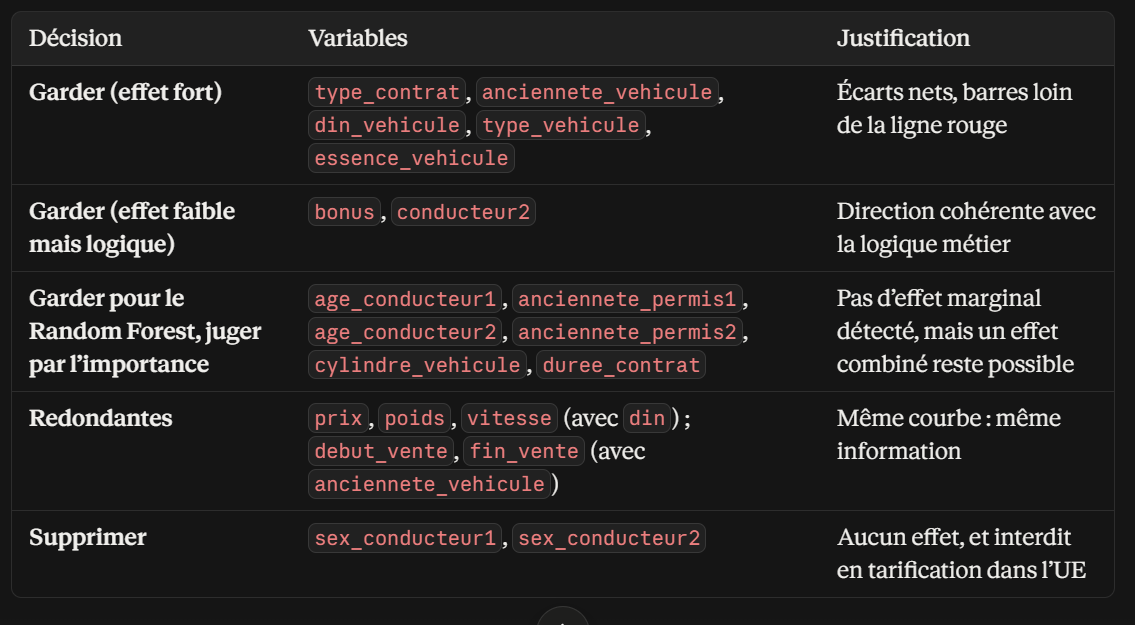

- lien avec montant_sinistre

In [9]:
sin = initial_train_set[initial_train_set["nombre_sinistres"] > 0].copy()

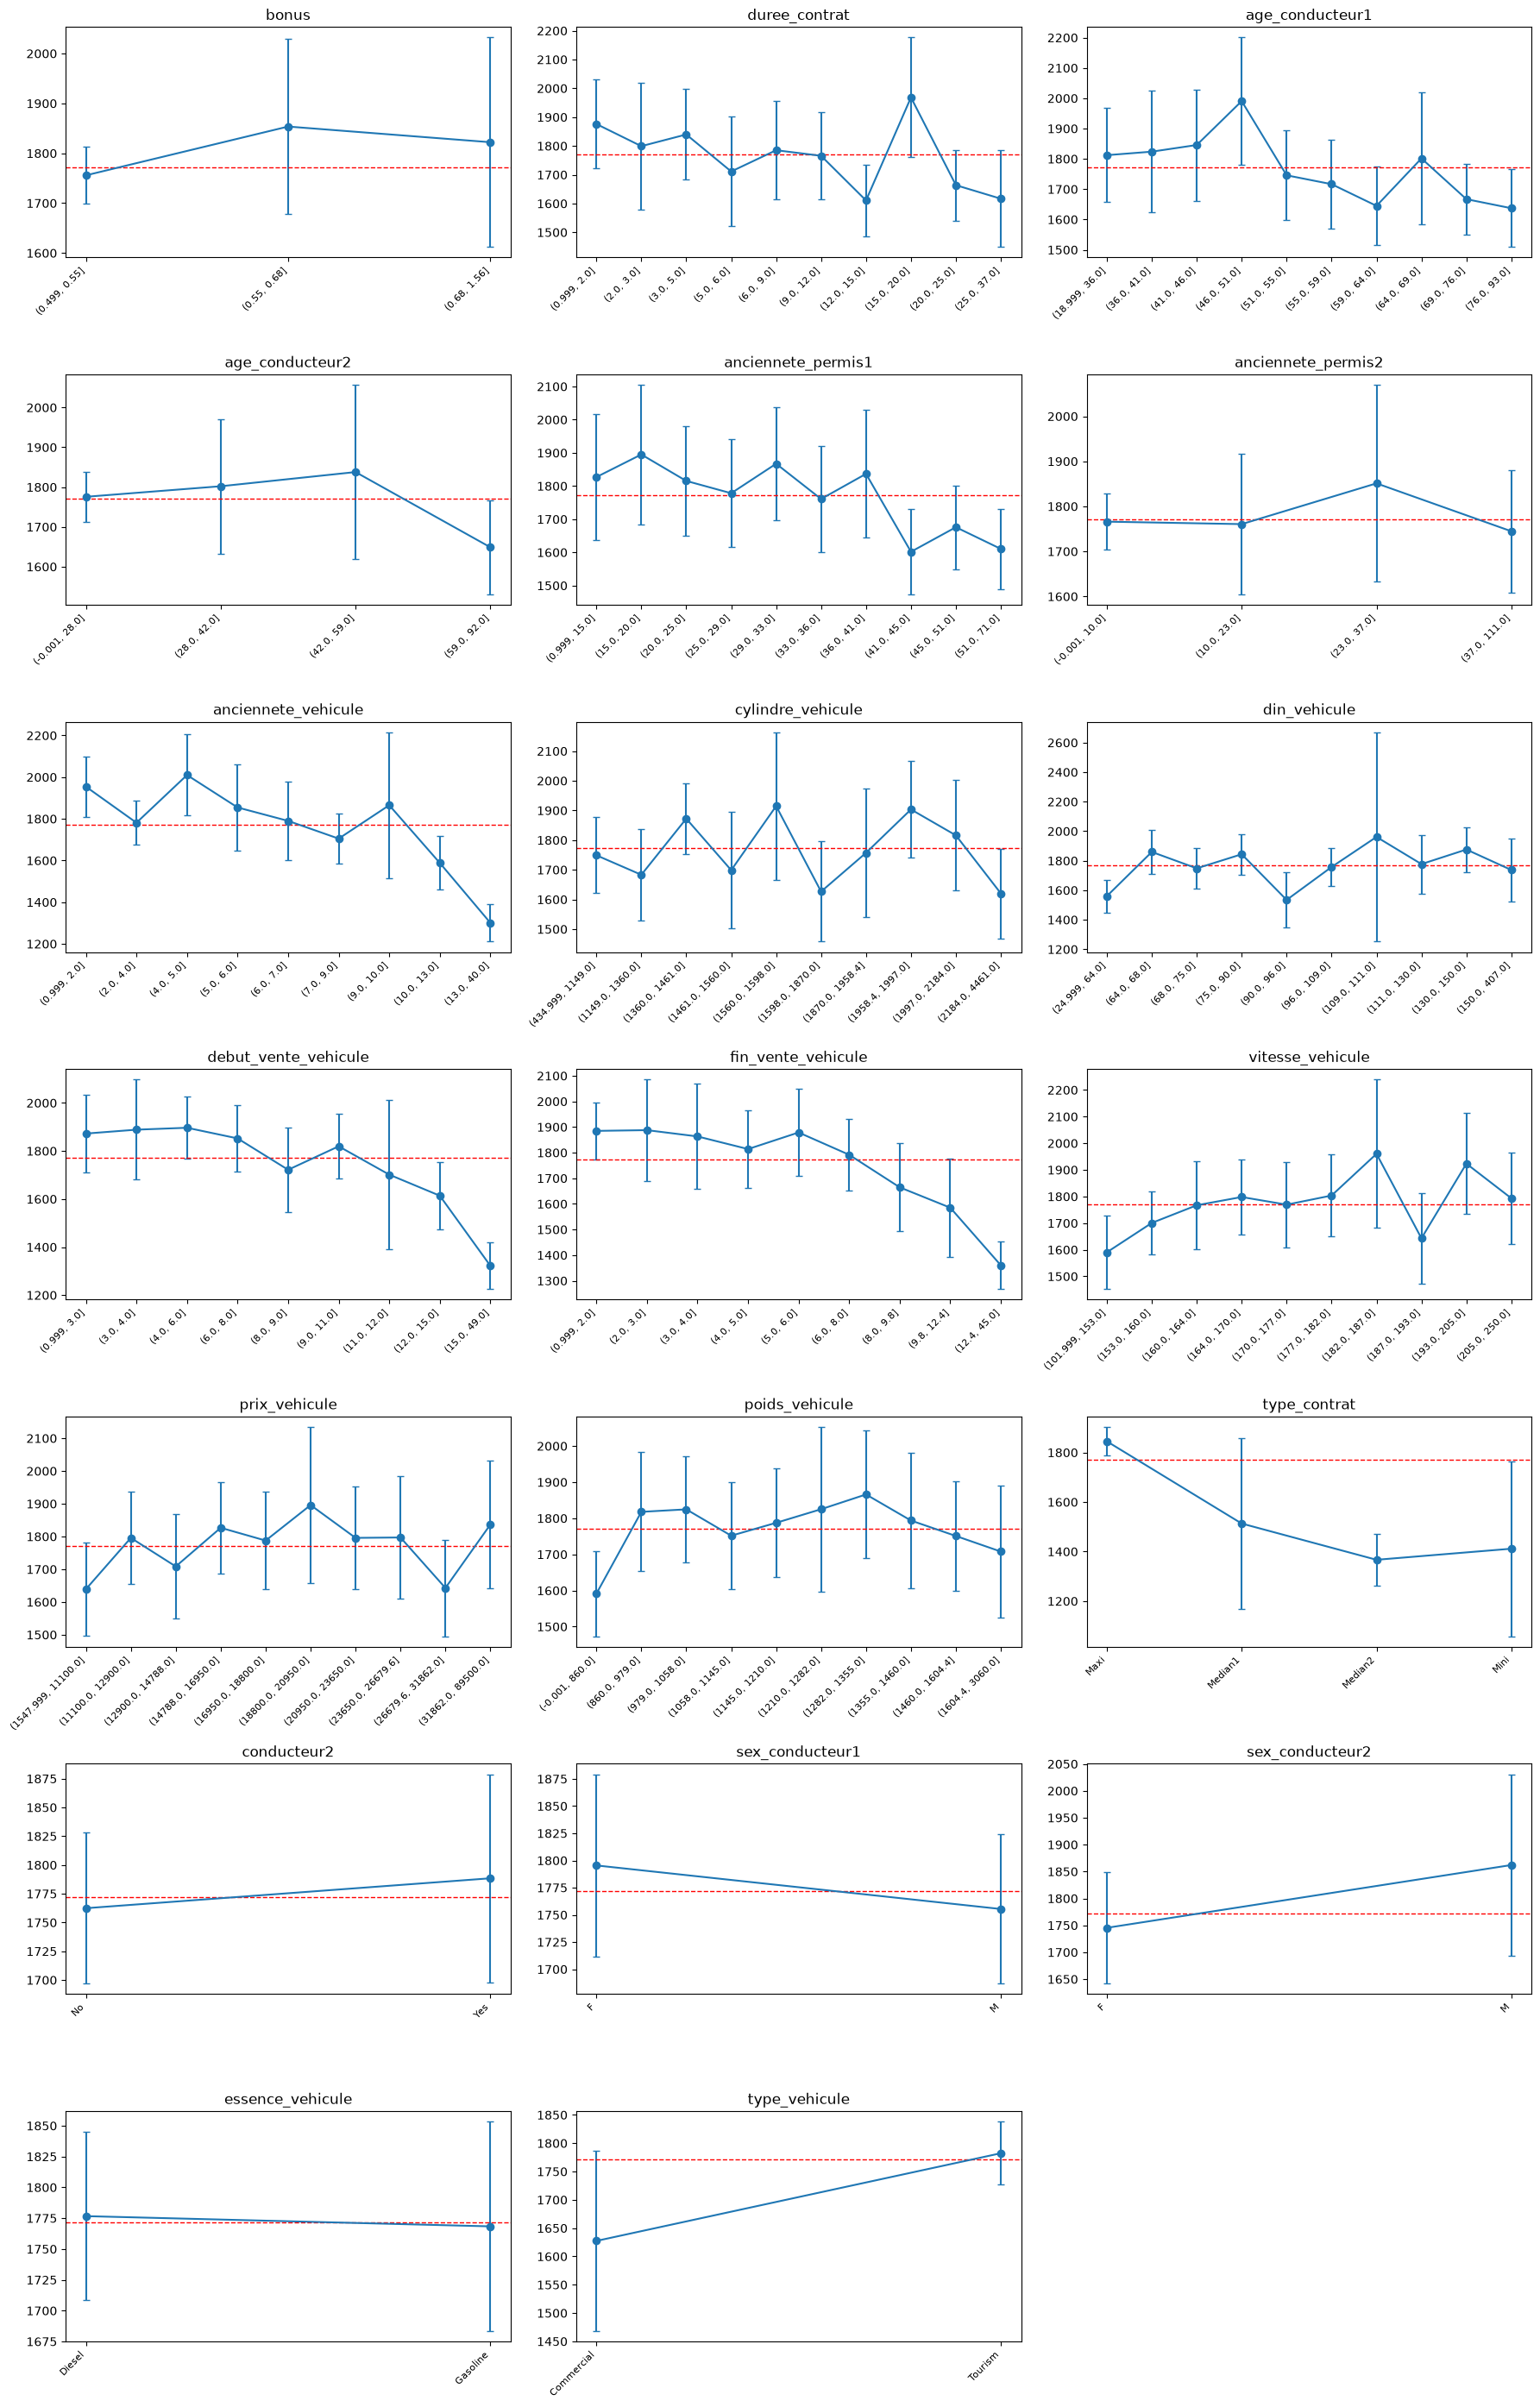

In [10]:
ncol = 3; nrow = int(np.ceil(len(variables) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 4 * nrow), squeeze=False)
moy_globale = sin["montant_sinistre"].mean()

for ax, (c, b) in zip(axes.flat, variables):
    x = pd.qcut(sin[c], q=b, duplicates="drop") if b else sin[c]
    g = sin.groupby(x, observed=True)["montant_sinistre"].agg(["mean", "std", "count"])
    g = g[g["count"] >= 30]
    g["ic95"] = 1.96 * g["std"] / np.sqrt(g["count"])
    ax.errorbar(range(len(g)), g["mean"], yerr=g["ic95"], fmt="o-", capsize=3)
    ax.axhline(moy_globale, color="red", ls="--", lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(c)
for ax in axes.flat[len(variables):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

- classement des variables par force de lien 

In [13]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

res = []
for c in cols_num:
    rho = spearmanr(train[c], train["sinistre"], nan_policy="omit")[0]
    res.append((c, "num", abs(rho)))
for c in cols_cat:
    res.append((c, "cat", cramers_v(train[c].fillna("NA"), train["sinistre"])))

display(pd.DataFrame(res, columns=["variable", "type", "force_lien"])
        .sort_values("force_lien", ascending=False).round(3))

,variable,type,force_lien
9,debut_vente_vehicule,num,0.102
6,anciennete_vehicule,num,0.100
10,fin_vente_vehicule,num,0.099
14,type_contrat,cat,0.096
8,din_vehicule,num,0.078
12,prix_vehicule,num,0.077
11,vitesse_vehicule,num,0.070
13,poids_vehicule,num,0.068
18,essence_vehicule,cat,0.037
7,cylindre_vehicule,num,0.035


- redondance entre variables explicatives

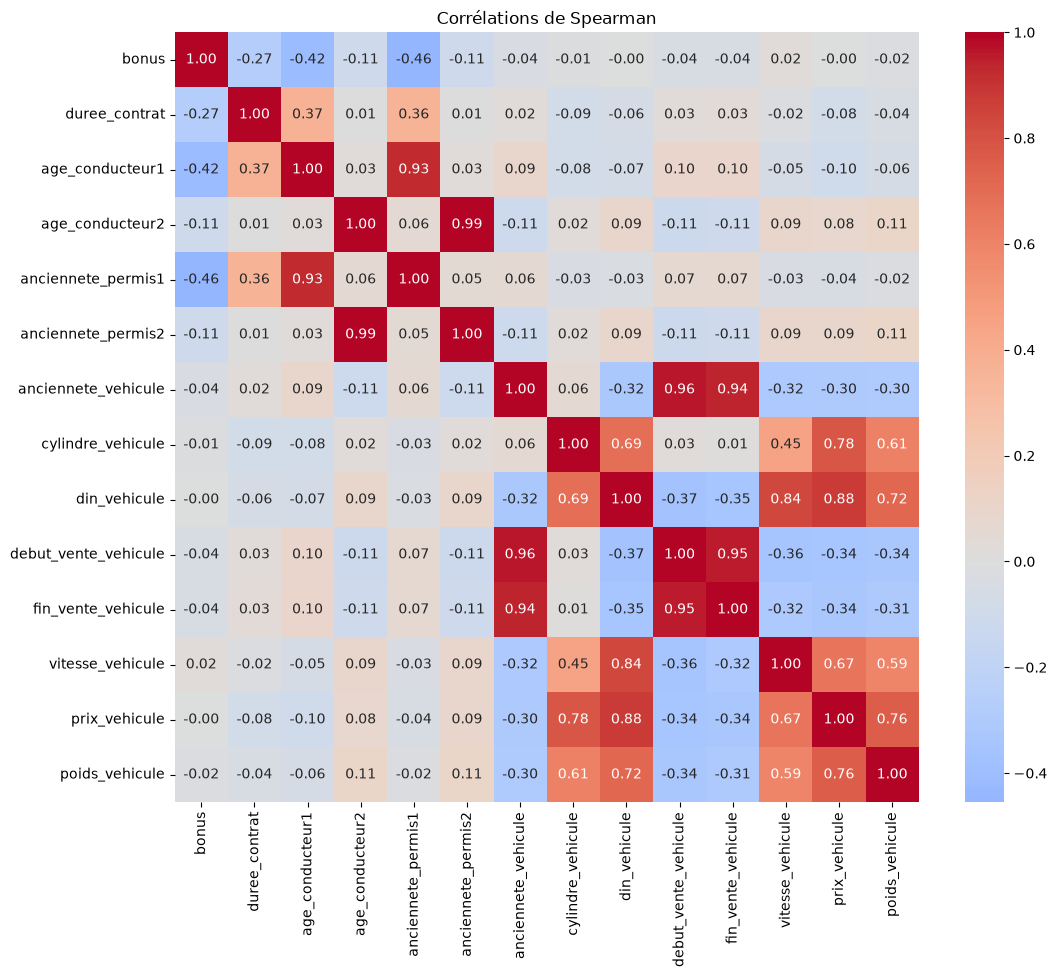

age_conducteur2       anciennete_permis2      0.990251
anciennete_vehicule   debut_vente_vehicule    0.960990
debut_vente_vehicule  fin_vente_vehicule      0.949308
anciennete_vehicule   fin_vente_vehicule      0.941719
age_conducteur1       anciennete_permis1      0.925187
din_vehicule          prix_vehicule           0.875441
                      vitesse_vehicule        0.839037
cylindre_vehicule     prix_vehicule           0.784447
prix_vehicule         poids_vehicule          0.760734
din_vehicule          poids_vehicule          0.720049
dtype: float64


In [ ]:
corr = train[cols_num].corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations de Spearman"); plt.show()

paires = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(paires[paires.abs() > 0.7].sort_values(ascending=False))